In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 1. Data analysis and visualization of last 365 days

In [2]:
df365 = pd.read_csv('cleaned_LagankhelLast365days.csv')
df365

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,49.169250,%,2025-10-12 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,47.179417,%,2025-10-12 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,45.503514,%,2025-10-12 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,43.669944,%,2025-10-12 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,41.028250,%,2025-10-12 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-10-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,48.523667,%,2025-11-27 03:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,03:45:00
996,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,48.527333,%,2025-11-27 04:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,04:45:00
997,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,48.756625,%,2025-11-27 05:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,05:45:00
998,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,48.326333,%,2025-11-27 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2025-11-27,06:45:00


In [3]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df365.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [4]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2025-10-12,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,40.92,18
1,2025-10-13,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,40.15,24
2,2025-10-14,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,41.44,24
3,2025-10-15,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,42.34,24
4,2025-10-16,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,42.73,24
5,2025-10-17,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,46.53,24
6,2025-10-18,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,45.51,24
7,2025-10-19,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,44.10,24
8,2025-10-20,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,40.72,21
9,2025-10-21,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,38.68,24


/tmp/ipykernel_44525/2403254589.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


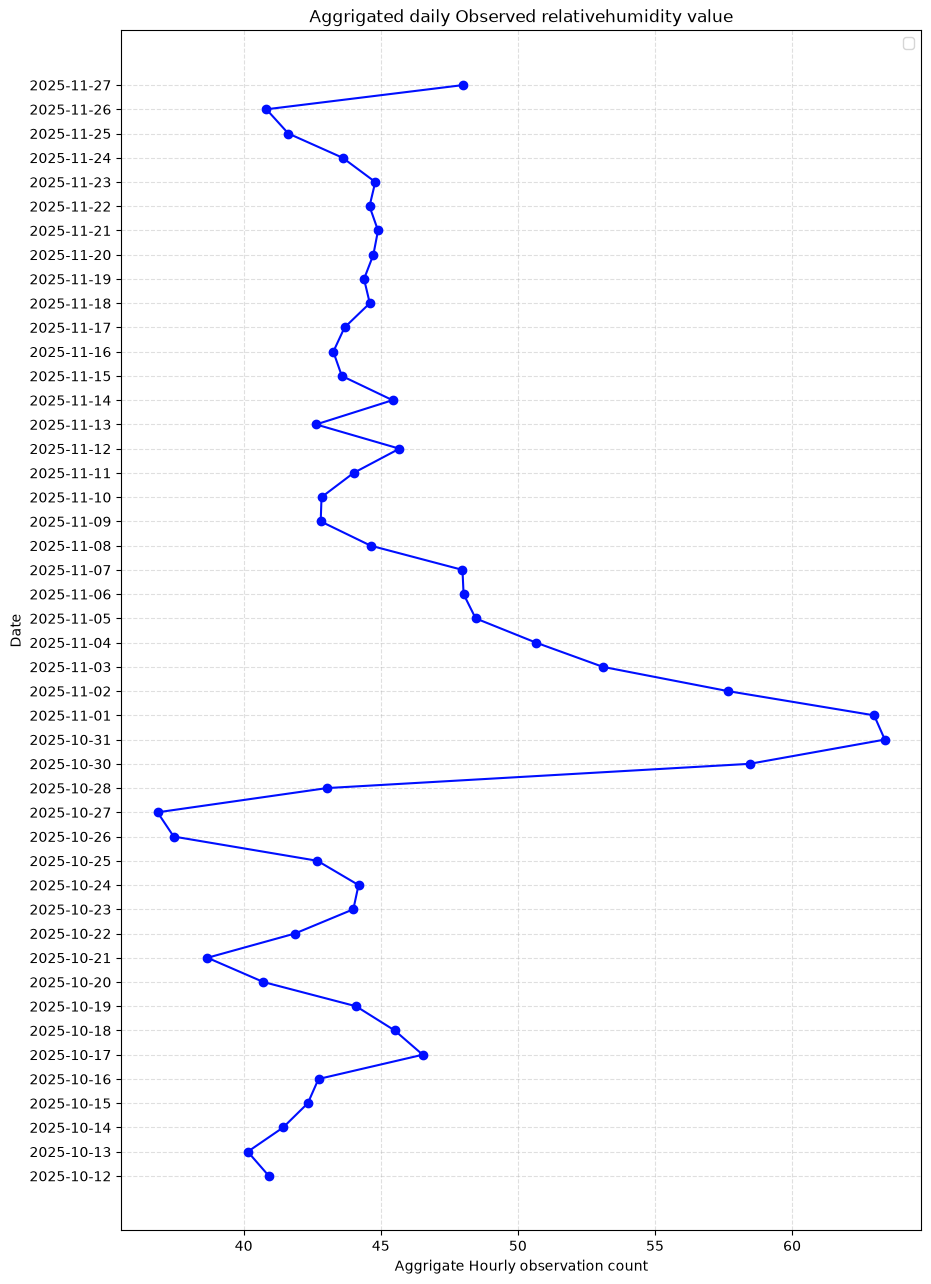

In [5]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 2. Data Analysis and Visualization of last 30 days

In [6]:
df30 = pd.read_csv('cleaned_LagankhelLast30days.csv')
df30

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,58.0,%,2026-09-12 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,57.0,%,2026-09-12 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,55.0,%,2026-09-12 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,53.0,%,2026-09-12 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,51.0,%,2026-09-12 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-09-12,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
715,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,54.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
716,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,54.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
717,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,55.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
718,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,55.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [7]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df30.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [8]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-09-12,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,52.06,18
1,2026-09-13,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,52.54,24
2,2026-09-14,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,52.71,24
3,2026-09-15,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,52.54,24
4,2026-09-16,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,53.38,24
5,2026-09-17,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,51.75,24
6,2026-09-18,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,52.54,24
7,2026-09-19,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,51.88,24
8,2026-09-20,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,51.58,24
9,2026-09-21,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,53.08,24


/tmp/ipykernel_44525/1124759186.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


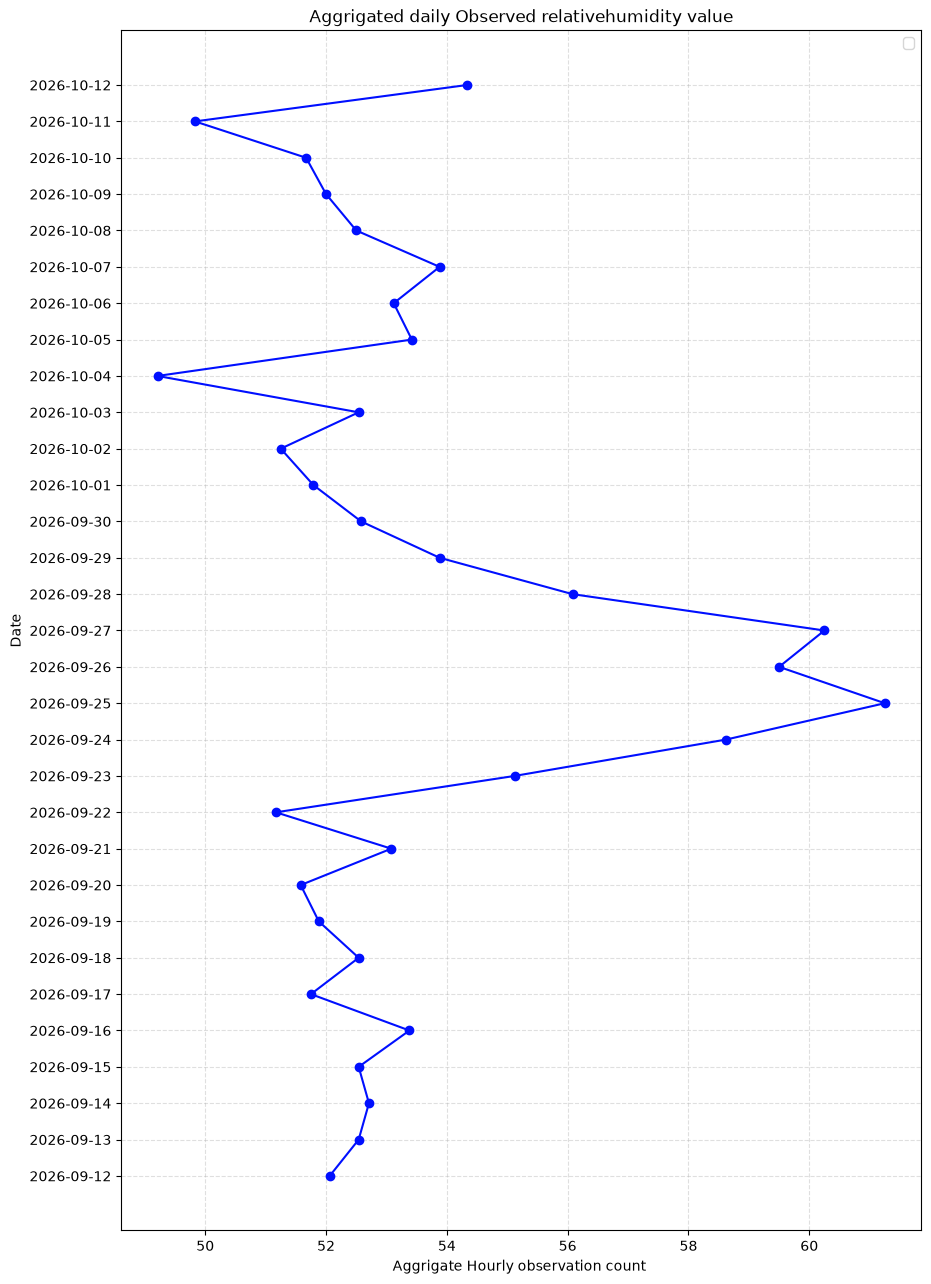

In [9]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 3. Data Analysis and Visualization of last 7 days

In [10]:
df7 = pd.read_csv('cleaned_LagankhelLast7days.csv')
df7

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,54.0,%,2026-10-05 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,54.0,%,2026-10-05 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,52.0,%,2026-10-05 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,51.0,%,2026-10-05 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,50.0,%,2026-10-05 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-05,10:45:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,54.0,%,2026-10-12 01:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,01:45:00
164,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,54.0,%,2026-10-12 02:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,02:45:00
165,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,55.0,%,2026-10-12 03:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,03:45:00
166,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,55.0,%,2026-10-12 04:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-12,04:45:00


In [12]:
# Group records by local calendar date and calculate the daily mean humidity.
# `value` becomes the mean relative humidity for that day.
daily_means = (
    df7.groupby(
        ["date", "location_id", "location_name", "parameter", "unit",
         "timezone", "latitude", "longitude", "owner_name", "provider"],
        as_index=False
    )
    .agg(
        value=("value", "mean"),              # daily average humidity
        observation_count=("value", "count")  # readings included that day
    )
)

# Optional: round the daily mean to two decimal places
daily_means["value"] = daily_means["value"].round(2)

In [13]:
daily_means

,date,location_id,location_name,parameter,unit,timezone,latitude,longitude,owner_name,provider,value,observation_count
0,2026-10-05,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,53.22,18
1,2026-10-06,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,53.12,24
2,2026-10-07,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,53.88,24
3,2026-10-08,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,52.50,24
4,2026-10-09,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,52.00,24
5,2026-10-10,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,51.67,24
6,2026-10-11,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,49.83,24
7,2026-10-12,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,%,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,54.33,6


/tmp/ipykernel_44525/3434928225.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


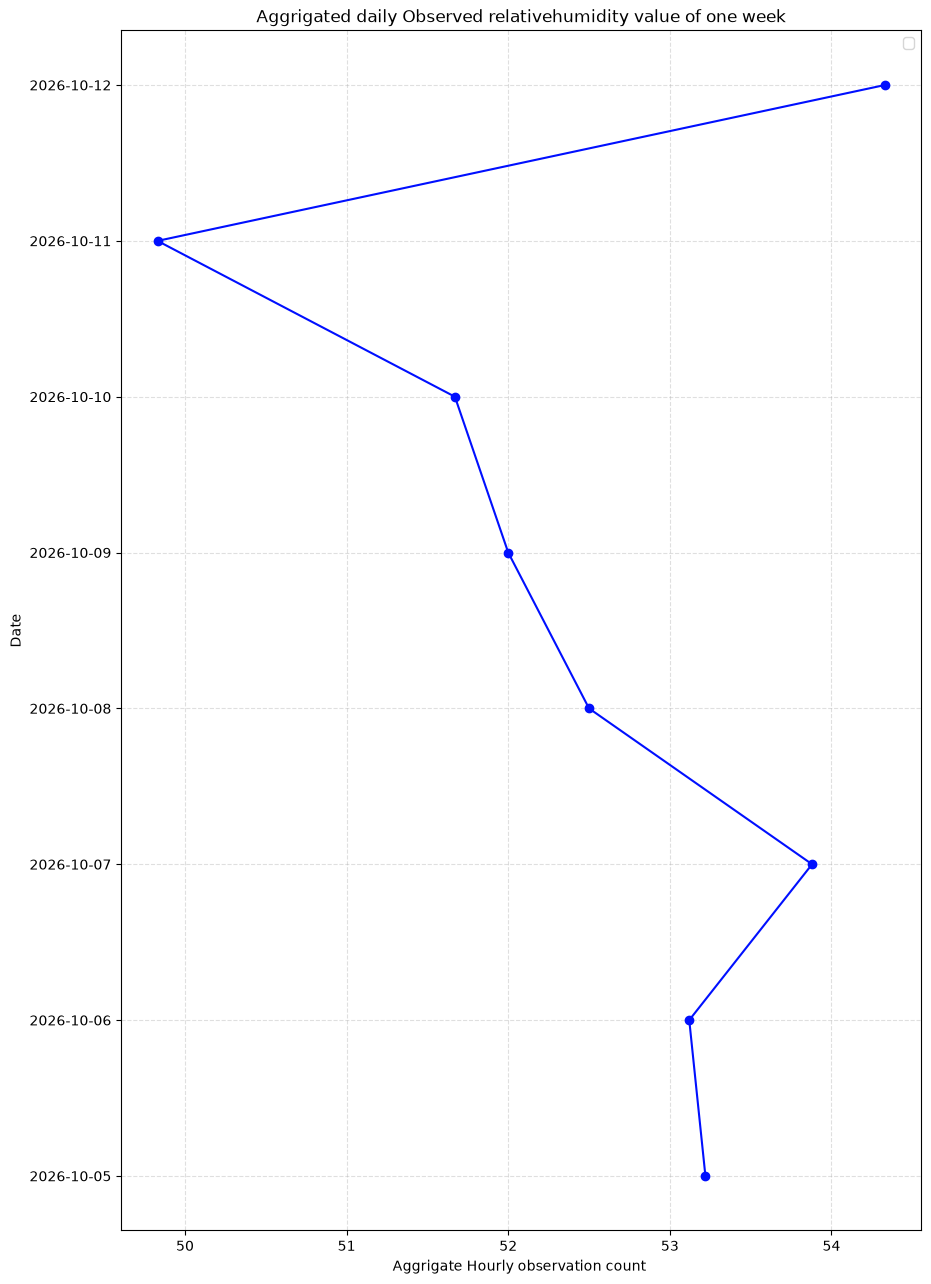

In [14]:
fig = plt.figure(figsize=(10, 15))
ax = fig.add_axes([0.1, 0.1, 0.8, 0.8])
ax.plot(daily_means['value'], daily_means['date'], color ='#000fff', marker='o')
plt.xlabel('Aggrigate Hourly observation count ')
plt.ylabel('Date')
plt.title("Aggrigated daily Observed relativehumidity value of one week")
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()

## 4. Data Analysis and Visualization of last 24 hours

In [15]:
df24 = pd.read_csv('cleaned_LagankhelLast24hours.csv')
df24

,location_id,location_name,parameter,value,unit,datetimeLocal,timezone,latitude,longitude,owner_name,provider,date,time
0,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,56.0,%,2026-10-11 06:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,06:45:00
1,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,56.0,%,2026-10-11 07:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,07:45:00
2,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,54.0,%,2026-10-11 08:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,08:45:00
3,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,51.0,%,2026-10-11 09:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,09:45:00
4,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,48.0,%,2026-10-11 10:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,10:45:00
5,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,45.0,%,2026-10-11 11:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,11:45:00
6,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,43.0,%,2026-10-11 12:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,12:45:00
7,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,42.0,%,2026-10-11 13:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,13:45:00
8,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,40.0,%,2026-10-11 14:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,14:45:00
9,5509788,Lagankhel (SC - 05) - GD Labs,relativehumidity,38.0,%,2026-10-11 15:45:00+05:45,Asia/Kathmandu,27.666459,85.323093,Green Decision Labs and Research,AirGradient,2026-10-11,15:45:00


/tmp/ipykernel_44525/1036584907.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


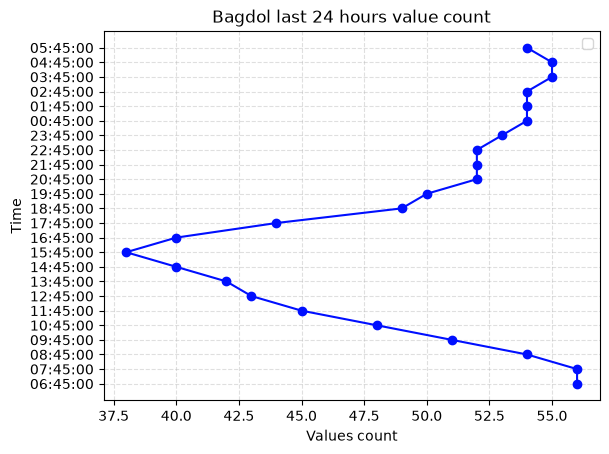

In [16]:
# Line Plot
plt.plot(df24['value'], df24['time'], color='#000fff', marker='o')
plt.xlabel('Values count')
plt.ylabel('Time')
plt.title('Bagdol last 24 hours value count')
plt.grid(linestyle='--', alpha=0.4)
plt.legend()
plt.show()